In [ ]:
import os

os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo
import matplotlib.pyplot as plt
import numpy as np

import pyrite

_ = pyrite.fetch_tables()
tables_ready = True

# Will the PXR line survive my detector?

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/15-pxr-signal-background.py)

Compare a **30 keV electron beam on 1 µm HOPG**, with and without a
**2 µm silicon filter**, through a Timepix3 response. Follow the photons
from source density to transmitted flux to expected measured counts.
A visible source peak does not guarantee a visible measured peak.

Run locally with `uv run marimo edit docs/notebooks/15-pxr-signal-background.py`,
or use Molab's inline environment. The first cell installs missing reference
tables once (about 100 MB); later runs reuse them. This bounded CPU example
uses **2048 CXR / 512 bremsstrahlung histories**, transport seed **23**,
up to six reflection families and **one angular tile** on a small detector patch.
It is a design exercise, not a convergence study. The physical beam is
**0.01 pC at 1 MHz (10 nA)**; those electrons are distinct from the sampled
histories. Restart the kernel to change the backend.

In [ ]:
from pyrite import Scene, simulate
from pyrite.beams import Beam, PointBunch, PointSpot
from pyrite.detectors import PixelGrid, PlanarDetector, PlanarPose
from pyrite.geometry import FilterPlate, Footprint, Slab
from pyrite.units import ureg

beam = Beam(
    kinetic_energy=30 * ureg.keV,
    transverse=PointSpot(),
    longitudinal=PointBunch(),
    bunch_charge_pc=0.01 * ureg.pC,
    rep_rate_hz=1 * ureg.MHz,
)
panel = PlanarDetector(
    PlanarPose.from_observation(100 * ureg.mm, 135 * ureg.degree),
    pixels=PixelGrid((1, 1), (2 * ureg.mm, 2 * ureg.mm)),
)
target = Slab(
    "hopg",
    1 * ureg.um,
    tilt_deg=30 * ureg.degree,
    footprint=Footprint(5 * ureg.mm, 5 * ureg.mm),
)
silicon_filter = FilterPlate(
    "silicon",
    thickness_mm=2 * ureg.um,
    size_mm=(4 * ureg.mm, 4 * ureg.mm),
    pose=PlanarPose.from_observation(50 * ureg.mm, 135 * ureg.degree),
)
scenes = {
    "Open": Scene(beam, target, panel),
    "Si filter": Scene(beam, target, panel, filters=(silicon_filter,)),
}

## Configure the readout independently

The single **2 × 2 mm patch at 100 mm** integrates a small acceptance; it
is a spatial bin, not a physical Timepix pixel. The response models a
**500 µm silicon sensor at 100 V**, with absorption, charge sharing,
energy noise and an approximately **1.9 keV counting threshold**.
These are illustrative sensor conditions, not a calibrated detector.

Response input channels are **50 eV**, native measured bins **25 eV**,
with **60,000 photons per input channel** and matrix seed **19**.
Acquisition reporting bins are separately chosen at **25 eV** from
**0–10 keV**. We request expected counts for **1 s**, without a Poisson
realization, to expose the mean spectrum. Photons outside the reporting
range and losses below threshold are not counted here.

In [ ]:
from pyrite.config import (
    AngularSampling,
    CxrReflections,
    FixedSampling,
    Numerics,
    Timepix3ResponseNumerics,
)
from pyrite.detectors import Timepix3Response
from pyrite.observations import Acquisition, Observation

acquisition = Acquisition(
    exposure_s=1 * ureg.s,
    measured_edges_eV=tuple(np.arange(0, 10_001, 25)),
    mode="expected",
)
observation = Observation(
    detector="detector",
    response=Timepix3Response(
        thickness_um=500 * ureg.um,
        bias_v=100 * ureg.V,
        numerics=Timepix3ResponseNumerics(seed=19),
    ),
    sampling=AngularSampling((1, 1)),
    acquisition=acquisition,
)
numerics = Numerics(
    seed=23,
    sampling=FixedSampling(cxr_electrons=2048, brem_electrons=512),
    cxr_reflections=CxrReflections(n_families=6),
)

In [ ]:
assert tables_ready
results = {
    name: simulate(scene, observation=observation, numerics=numerics)
    for name, scene in scenes.items()
}

## Inspect each stage on its own energy axis

The open result supplies source density before any downstream filter.
`spatial.spectra(measured=False)` includes geometric acceptance and filter
attenuation, but no sensor response. Multiplying once by the physical
electron rate gives transmitted photons/(s eV).
`acquire()` already includes that normalization and exposure: **do not
multiply its counts by beam current or solid angle again**.

PXR and CBS interfere, so their combined `cxr` component is the signal.
Bremsstrahlung and characteristic radiation form the modeled background.
Each source component retains its own true-energy grid; measured spectra
share the acquisition reporting bins. Carbon characteristic emission is
soft and largely rejected by this response.

In [ ]:
components = {"cxr": "PXR + CBS", "brem": "Bremsstrahlung", "characteristic": "Characteristic"}
electron_rate = (beam.bunch_charge_pc * ureg.pC / ureg.elementary_charge).to(
    ""
).magnitude * beam.rep_rate_hz
transmitted = {}
counts = {}
for _name, _result in results.items():
    for _component in components:
        _energy, _spectra = _result.spatial.spectra(
            region=(slice(None), slice(None)),
            component=_component,
        )
        transmitted[_name, _component] = (_energy, _spectra.sum(axis=0) * electron_rate)
        _batch = _result.acquire(
            region=(slice(None), slice(None)),
            components=(_component,),
        )
        counts[_name, _component] = _batch.expected.sum(axis=0)
measured_edges = _batch.measured_edges_eV

In [ ]:
band_start = mo.ui.slider(
    1000,
    3000,
    step=25,
    value=1400,
    label="Line-band lower edge (eV)",
)
band_start  # noqa: B018 - marimo displays the control

&lt;marimo-slider data-initial-value=&#x27;1400&#x27; data-label=&#x27;&amp;quot;&amp;#92;u003cspan class=&amp;#92;&amp;quot;markdown prose dark:prose-invert contents&amp;#92;&amp;quot;&amp;#92;u003e&amp;#92;u003cspan class=&amp;#92;&amp;quot;paragraph&amp;#92;&amp;quot;&amp;#92;u003eLine-band lower edge (eV)&amp;#92;u003c/span&amp;#92;u003e&amp;#92;u003c/span&amp;#92;u003e&amp;quot;&#x27; data-start=&#x27;1000&#x27; data-stop=&#x27;3000&#x27; data-step=&#x27;25&#x27; data-steps=&#x27;[]&#x27; data-debounce=&#x27;false&#x27; data-disabled=&#x27;false&#x27; data-orientation=&#x27;&amp;quot;horizontal&amp;quot;&#x27; data-show-value=&#x27;false&#x27; data-include-input=&#x27;false&#x27; data-full-width=&#x27;false&#x27;&gt;&lt;/marimo-slider&gt;

In [ ]:
line_band = (band_start.value, band_start.value + 800)
side_bands = ((line_band[0] - 400, line_band[0]), (line_band[1], line_band[1] + 400))

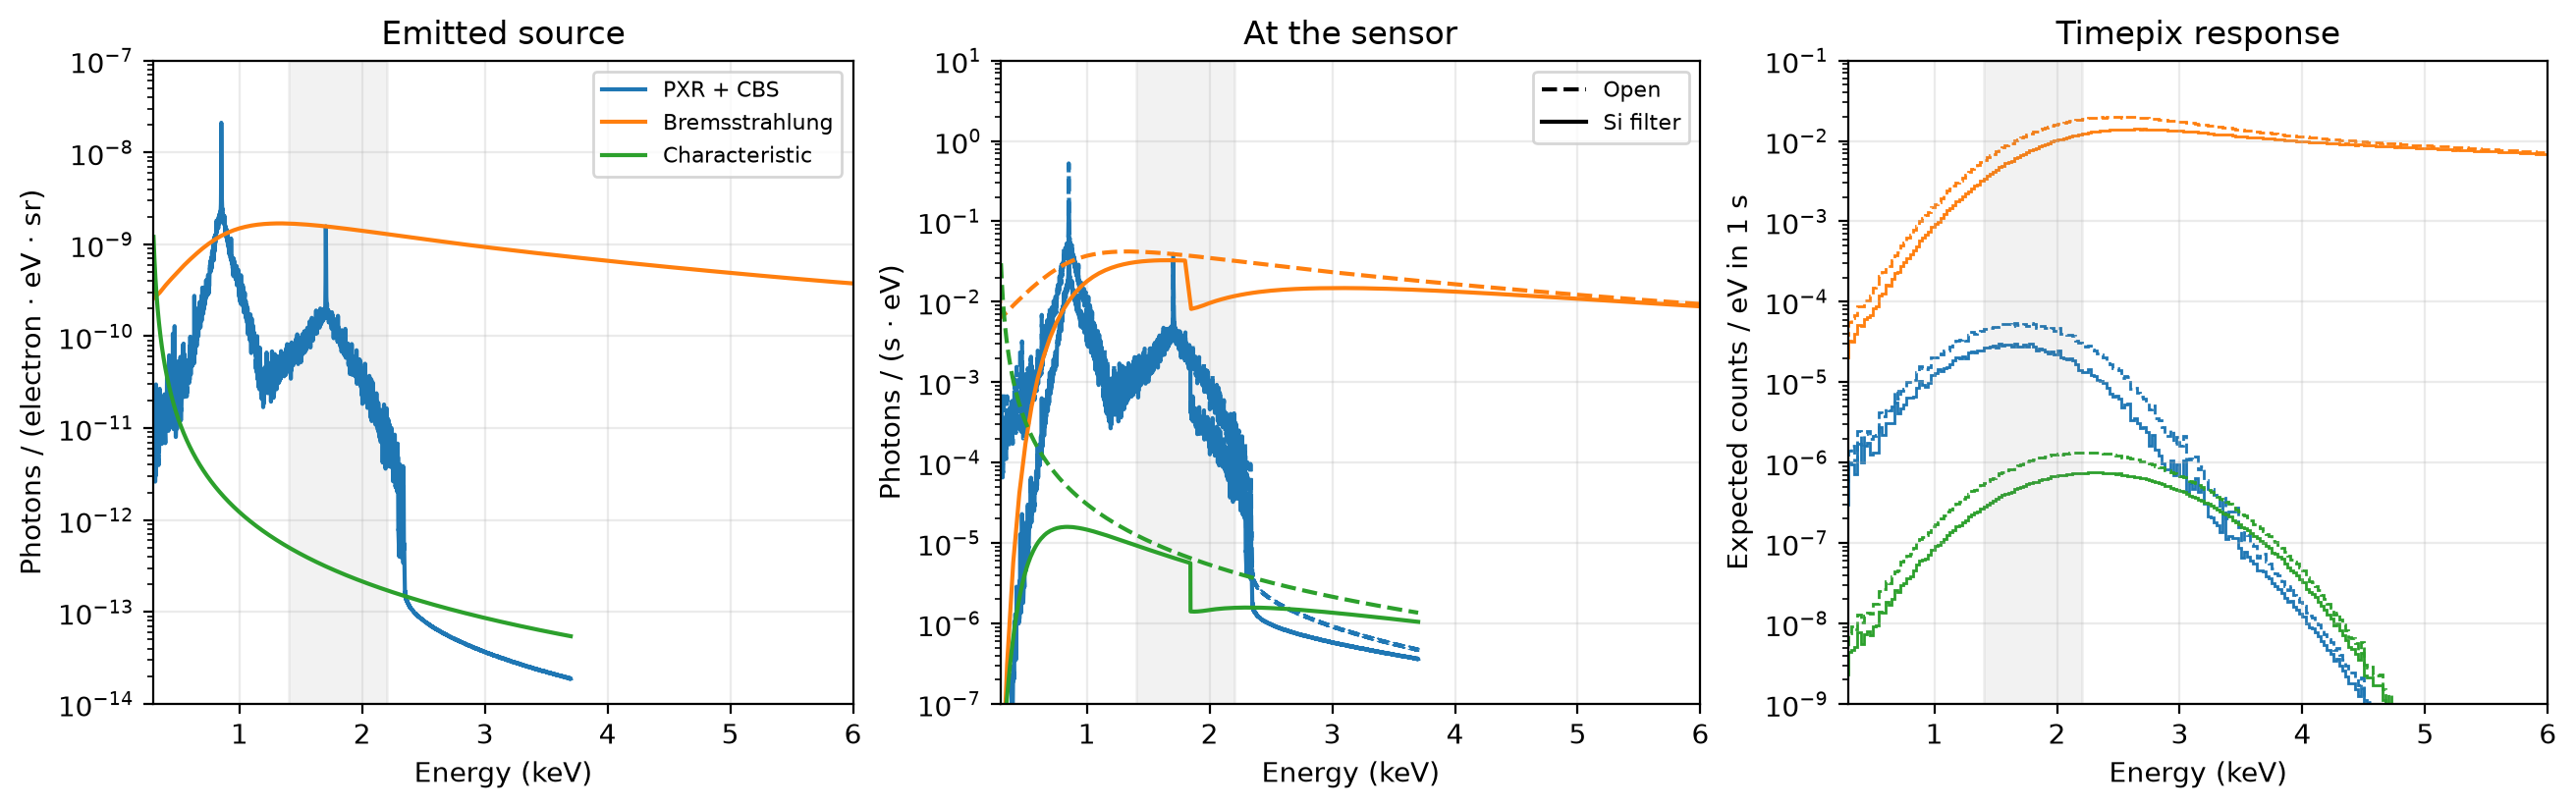

In [ ]:
figure, _axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
_source = results["Open"]
_native = {
    "cxr": _source.cxr.incoherent,
    "brem": _source.brem,
    "characteristic": _source.characteristic,
}
for _color, (_component, _label) in zip(("C0", "C1", "C2"), components.items(), strict=True):
    _spectrum = _native[_component]
    _axes[0].plot(_spectrum.photon_energy_eV / 1000, _spectrum.density, color=_color, label=_label)
    for _name, _style in (("Open", "--"), ("Si filter", "-")):
        _energy, _flux = transmitted[_name, _component]
        _axes[1].plot(_energy / 1000, _flux, color=_color, ls=_style)
        _axes[2].stairs(
            counts[_name, _component] / np.diff(measured_edges),
            measured_edges / 1000,
            color=_color,
            ls=_style,
        )
for _ax, _title, _ylabel in zip(
    _axes,
    (
        "Emitted source",
        "At the sensor",
        "Timepix response",
    ),
    ("Photons / (electron · eV · sr)", "Photons / (s · eV)", "Expected counts / eV in 1 s"),
    strict=True,
):
    _ax.set(xlabel="Energy (keV)", ylabel=_ylabel, title=_title, xlim=(0.3, 6), yscale="log")
    _ax.grid(alpha=0.25)
_axes[0].set_ylim(1e-14, 1e-7)
_axes[1].set_ylim(1e-7, 10)
_axes[2].set_ylim(1e-9, 0.1)
for _ax in _axes:
    _ax.axvspan(line_band[0] / 1000, line_band[1] / 1000, color="grey", alpha=0.1)
_axes[1].plot([], [], "k--", label="Open")
_axes[1].plot([], [], "k-", label="Si filter")
_axes[1].legend(fontsize=8)
_axes[0].legend(fontsize=8)
figure  # noqa: B018 - marimo captures the final expression

## Measure a line-band excess

By default, use measured-energy **[1.4, 2.2) keV** around the second source line
near **1.7 keV**, with side bands **[1.0, 1.4)** and **[2.2, 2.6) keV**.
Estimate the background in the line band as the side-band counts times
the ratio of widths (here one). The displayed excess/background is
`(line-band total − estimated background) / estimated background`.
In a live session, move the slider to test that estimate without rerunning
transport. The static capture shows the default bands.

Also compare the **model-separated S/B**: measured CXR counts divided by
measured bremsstrahlung + characteristic counts inside the line band.
The grey region in the figure marks the line band.
This uses simulation labels unavailable to an experiment. Side bands can
contain broadened signal and a threshold-shaped continuum; the two
ratios need not agree. Neither ratio is a detection significance.

In [ ]:
_centres = (measured_edges[:-1] + measured_edges[1:]) / 2
_line_mask = (_centres >= line_band[0]) & (_centres < line_band[1])
_side_mask = np.zeros(_centres.size, dtype=bool)
for _low, _high in side_bands:
    _side_mask |= (_centres >= _low) & (_centres < _high)
_width_ratio = (line_band[1] - line_band[0]) / sum(b - a for a, b in side_bands)
_rows = []
for _name in ("Open", "Si filter"):
    _signal = counts[_name, "cxr"]
    _background = counts[_name, "brem"] + counts[_name, "characteristic"]
    _total = _signal + _background
    _s = _signal[_line_mask].sum()
    _b = _background[_line_mask].sum()
    _side_background = _total[_side_mask].sum() * _width_ratio
    _rows.append(
        f"<tr><th scope='row'>{_name}</th><td>{_s:.3g}</td><td>{_b:.3g}</td>"
        f"<td>{_s / _b:.3g}</td><td>{_total[_line_mask].sum():.3g}</td>"
        f"<td>{(_total[_line_mask].sum() - _side_background) / _side_background:.3g}</td></tr>"
    )
mo.Html(
    "<table><caption>Expected counts per 1 s exposure; half-open measured-energy bands.</caption>"
    "<thead><tr><th scope='col'>Configuration</th><th scope='col'>CXR signal S</th>"
    "<th scope='col'>Background B</th><th scope='col'>Model S/B</th>"
    "<th scope='col'>Band total</th><th scope='col'>Side-band excess/B</th></tr></thead>"
    "<tbody>" + "".join(_rows) + "</tbody></table>"
)

Configuration,CXR signal S,Background B,Model S/B,Band total,Side-band excess/B
Open,0.0377,9.95,0.00379,9.98,0.0879
Si filter,0.0202,6.18,0.00326,6.2,0.0135


## What does this say about an experiment?

The dominant source line near **0.85 keV** falls below the Timepix
threshold; the second line near **1.7 keV** is also strongly affected.
The captured example does **not** predict a resolved line above background.
A filter cannot recover photons rejected by the readout. Silicon attenuation is
energy-dependent, including its K edge near **1.84 keV**: it removes
photons from both signal and background. It cannot distinguish mechanisms
at the same true energy. Redistribution broadens features and moves some
higher-energy background into the reporting band. A better ratio can
still accompany fewer signal counts; inspect both columns before
choosing an exposure or filter.

Source densities per electron are independent of beam-current calibration.
Ratios cancel a common exposure/current normalization, but still depend on
the source, filter and response models and on the selected bands. Absolute
counts assume the stated current, geometry and exposure. At the default bands, the silicon filter reduces the model-separated S/B; the
positive side-band excess mostly reflects the continuum shape, not CXR.
More exposure scales S and B together; it does not improve their ratio. Monte Carlo
uncertainty, detector calibration uncertainty, pile-up/dead time,
environmental background and filter fluorescence/scatter into the sensor
are outside this calculation. The filter model is primary narrow-beam
attenuation only.

The **detector-timepix hardware claim remains unverified**, with placeholder
hardware parameters; native-bin bookkeeping checks are not calibration.
The **pixel-acquisition-counting** claim also remains unverified.
Consult the [detector forward-model ledger](https://pyrite.readthedocs.io/en/latest/validation/ledger-detector-forward-models.html),
[response physics](https://pyrite.readthedocs.io/en/latest/physics/detectors/detector-response.html)
and [detector how-to](https://pyrite.readthedocs.io/en/latest/guides/detector-observations.html).

Before quantitative use, refine histories, angular tiles, response
discretization and reflection coverage, and inspect any optical-data
coverage warning. Try halving filter thickness or moving the side bands;
then compare a second transport seed. This tutorial adds no new detector
physics or experimental validation.

## Continue learning

- [From X-rays to detector counts](06-detector-counts.ipynb)
- [Acquire detector counts](../../guides/detector-observations.md)
- [Detector response physics](../../physics/detectors/detector-response.md)
- [Detector forward-model validation](../../validation/ledger-detector-forward-models.md)

{download}`Download canonical Marimo notebook <../15-pxr-signal-background.py>`